# Fase 3: efeito da Lei 14.300

Mede quanto o fim da regra antiga mudou o crescimento da potência adicionada por mês, separando isso
da desaceleração que já vinha desde 2020 (fase 2, seção 5).

Modelo: regressão com erros ARIMA sobre o log (FPP3 cap. 10), com variáveis de intervenção em datas fixadas
pelo calendário da lei (§7.4; Box & Tiao, 1975):

$$\log y_t = \beta' x_t + \eta_t, \qquad \eta_t \sim \text{ARIMA}(p,1,q) \text{ com drift}$$

Robustez: fim da corrida em jan/2023, modelo com tendência quebrada e erros estacionários (d = 0),
e contrafactual ajustado só até dez/2021.

Entrada: `data/processed/aneel_serie_mensal_uf.parquet`. Saída para a fase 5: `data/processed/fase3_choque_fim_corrida.csv`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
pd.set_option("display.precision", 3)

RES = ROOT / "resultados"
TODAS = UFS + ["SE"]
CORES = {**CORES_UF, "SE": estilo.TINTA}

serie = pd.read_parquet(ROOT / "data" / "processed" / "aneel_serie_mensal_uf.parquet")
y = {uf: g.set_index("mes")["log_mw"].asfreq("MS") for uf, g in serie.groupby("uf", observed=True)}
idx = y["SE"].index
print(f"{idx[0]:%Y-%m} a {idx[-1]:%Y-%m}, {len(idx)} meses por UF")

2016-01 a 2026-06, 126 meses por UF


## 1. Variáveis de intervenção

Como o modelo é em log, uma **rampa** (0, …, 0, 1, 2, 3, …) muda a inclinação, ou seja, a taxa de crescimento.
Um **degrau** (0, …, 0, 1, 1, …) muda o nível. As datas vêm do calendário, não dos dados.

| Variável | Forma | Liga em | Mede |
|---|---|---|---|
| `taxa_2020` | rampa | abr/2020 | desaceleração anterior à lei (quebra do Zivot-Andrews em MG e no Sudeste) |
| `taxa_corrida` | rampa | jan/2022 | mudança na taxa durante a corrida para garantir a regra antiga |
| `nivel_fim` | degrau | jul/2023 | queda de nível no fim da corrida |
| `taxa_fim` | rampa | jul/2023 | mudança na taxa depois da corrida |

A corrida vai de jan/2022 a jun/2023: o protocolo era até jan/2023 e a conexão da microgeração vinha alguns meses depois.
O drift do modelo é a taxa de 2016 até mar/2020. Cada coeficiente de rampa é a **mudança** em relação ao regime anterior.

In [2]:
def rampa(inicio):
    """0 antes de `inicio`, depois 1, 2, 3...: no log, muda a taxa de crescimento."""
    t0 = idx.get_loc(pd.Timestamp(inicio))
    return pd.Series(np.maximum(0, np.arange(len(idx)) - t0 + 1), index=idx, dtype=float)


def degrau(inicio):
    """0 antes de `inicio`, 1 depois: no log, muda o nível."""
    return pd.Series((idx >= pd.Timestamp(inicio)).astype(float), index=idx)


def intervencoes(fim_corrida="2023-06"):
    depois = pd.Timestamp(fim_corrida) + pd.offsets.MonthBegin(1)
    return pd.DataFrame({
        "taxa_2020": rampa("2020-04"),
        "taxa_corrida": rampa("2022-01"),
        "nivel_fim": degrau(depois),
        "taxa_fim": rampa(depois),
    })


LEI = ["taxa_corrida", "nivel_fim", "taxa_fim"]
X = intervencoes()
X.loc[["2020-03", "2020-04", "2021-12", "2022-01", "2023-06", "2023-07", "2023-08"]]

,taxa_2020,taxa_corrida,nivel_fim,taxa_fim
mes,,,,
2020-03-01,0.0,0.0,0.0,0.0
2020-04-01,1.0,0.0,0.0,0.0
2021-12-01,21.0,0.0,0.0,0.0
2022-01-01,22.0,1.0,0.0,0.0
2023-06-01,39.0,18.0,0.0,0.0
2023-07-01,40.0,19.0,1.0,1.0
2023-08-01,41.0,20.0,1.0,2.0


## 2. Ordens do ARIMA

A fase 2 apontou ARIMA(0,1,1) em todas as UFs, com ARIMA(1,1,0) e termo sazonal como candidatos em SP.
Aqui todas as UFs testam os mesmos vizinhos, já com as intervenções, e a ordem sai pelo menor AICc (§9.6).
A tabela mostra a diferença de AICc para o melhor modelo da UF (0 = escolhido).

In [3]:
CANDIDATOS = {
    "(0,1,1)": ((0, 1, 1), (0, 0, 0, 0)),
    "(1,1,0)": ((1, 1, 0), (0, 0, 0, 0)),
    "(1,1,1)": ((1, 1, 1), (0, 0, 0, 0)),
    "(0,1,2)": ((0, 1, 2), (0, 0, 0, 0)),
    "(0,1,1)(1,0,0)₁₂": ((0, 1, 1), (1, 0, 0, 12)),
    "(0,1,1)(0,0,1)₁₂": ((0, 1, 1), (0, 0, 1, 12)),
}


NAO_CONVERGIU = []


def ajustar(uf, X, ordem=(0, 1, 1), sazonal=(0, 0, 0, 0), ate=None):
    """Ajusta por máxima verossimilhança. Ajustes que não convergem vão para NAO_CONVERGIU."""
    yy, XX = (y[uf], X) if ate is None else (y[uf][:ate], X[:ate])
    trend = "t" if ordem[1] == 1 else "ct"  # com d = 1, o termo em t vira o drift
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        r = ARIMA(yy, exog=XX, order=ordem, seasonal_order=sazonal, trend=trend).fit(method_kwargs={"maxiter": 1000})
    if not r.mle_retvals["converged"]:
        NAO_CONVERGIU.append(f"{uf} {ordem}{sazonal if sazonal[3] else ''}")
    return r


aicc = pd.DataFrame({uf: {nome: ajustar(uf, X, *o).aicc for nome, o in CANDIDATOS.items()} for uf in TODAS}).T
ESCOLHA = {uf: CANDIDATOS[aicc.loc[uf].idxmin()] for uf in TODAS}
print("sem convergência:", NAO_CONVERGIU or "nenhum")
(aicc.sub(aicc.min(axis=1), axis=0)).round(1)

sem convergência: ['MG (0, 1, 1)']


,"(0,1,1)","(1,1,0)","(1,1,1)","(0,1,2)","(0,1,1)(1,0,0)₁₂","(0,1,1)(0,0,1)₁₂"
SP,0.5,0.0,1.5,1.7,1.7,2.1
MG,0.0,47.8,2.3,2.3,1.9,2.0
RJ,0.0,14.2,2.0,2.0,1.4,1.1
ES,6.6,19.1,3.4,0.0,7.2,7.1
SE,0.0,7.1,1.3,1.4,2.3,2.3


**Leitura.**
- O ARIMA(0,1,1) da fase 2 fica com o menor AICc em MG, RJ e no Sudeste. Em ES, o (0,1,2) é melhor por 6,6. Em SP, o (1,1,0) ganha do (0,1,1) por 0,5, uma diferença sem importância, mas é a ordem que o modelo de SP passa a usar.
- Em SP, os termos sazonais ficam 1,7 a 2,1 pontos atrás do (1,1,0). O termo sazonal que a fase 2 deixou para testar não entra.
- O (0,1,1) de MG aparece como "sem convergência": o MA(1) bate na fronteira de invertibilidade (θ = −1, seção 4). As estimativas são as mesmas da versão com d = 0, que não tem esse problema.
- Fora de SP, o (1,1,0) fica muito atrás (8 a 49 pontos). Isso confirma que a dependência é pelo erro (MA), não pelo valor passado (AR).

## 3. Estimativas

Os coeficientes são variações mensais no log. Para ler, a tabela converte em **crescimento anual da potência adicionada
por mês** em cada regime, $100\,(e^{12b}-1)$, e a queda de nível em %, com intervalos de 95%.

In [4]:
NAO_CONVERGIU.clear()
modelo = {uf: ajustar(uf, X, *ESCOLHA[uf]) for uf in TODAS}
print("sem convergência:", NAO_CONVERGIU or "nenhum")


def combinacao(r, pesos):
    """Média e erro-padrão de uma combinação linear dos coeficientes."""
    g = pd.Series(pesos, dtype=float).reindex(r.params.index, fill_value=0.0)
    return g @ r.params, np.sqrt(g @ r.cov_params() @ g)


def fmt(m, s, f):
    return f"{f(m):.0f}% [{f(m - 1.96 * s):.0f}; {f(m + 1.96 * s):.0f}]"


anual = lambda b: 100 * (np.exp(12 * b) - 1)
nivel = lambda b: 100 * (np.exp(b) - 1)
REGIMES = {
    "2016–mar/2020": {"drift": 1},
    "abr/2020–2021": {"drift": 1, "taxa_2020": 1},
    "corrida": {"drift": 1, "taxa_2020": 1, "taxa_corrida": 1},
    "depois de jul/2023": {"drift": 1, "taxa_2020": 1, "taxa_corrida": 1, "taxa_fim": 1},
}
tab_regimes = pd.DataFrame({
    uf: {**{nome: fmt(*combinacao(modelo[uf], p), anual) for nome, p in REGIMES.items()},
         "queda de nível em jul/2023": fmt(*combinacao(modelo[uf], {"nivel_fim": 1}), nivel)}
    for uf in TODAS}).T
tab_regimes

sem convergência: ['MG (0, 1, 1)']


,2016–mar/2020,abr/2020–2021,corrida,depois de jul/2023,queda de nível em jul/2023
SP,240% [118; 432],49% [-23; 191],6% [-49; 120],11% [-50; 144],-2% [-47; 81]
MG,207% [192; 222],18% [2; 36],66% [35; 102],-4% [-19; 12],-38% [-57; -9]
RJ,140% [78; 222],77% [-0; 214],26% [-36; 148],13% [-36; 101],-30% [-77; 116]
ES,194% [95; 343],80% [-39; 427],38% [-50; 284],31% [-38; 179],-41% [-81; 88]
SE,204% [143; 281],39% [-3; 101],36% [-8; 102],4% [-33; 62],-24% [-60; 45]


In [5]:
tab_coef = pd.DataFrame({uf: modelo[uf].params for uf in TODAS}).T
tab_p = pd.DataFrame({uf: modelo[uf].pvalues for uf in TODAS}).T
cols = ["drift", "taxa_2020"] + LEI
pd.concat({"coeficiente": tab_coef[cols], "p-valor": tab_p[cols]}, axis=1)

coeficiente                                              p-valor  \
         drift taxa_2020 taxa_corrida nivel_fim taxa_fim      drift   
SP       0.102    -0.069       -0.028    -0.016    0.004  7.927e-08   
MG       0.093    -0.080        0.028    -0.473   -0.046  0.000e+00   
RJ       0.073    -0.025       -0.028    -0.351   -0.009  7.776e-09   
ES       0.090    -0.041       -0.022    -0.523   -0.004  2.339e-07   
SE       0.093    -0.065       -0.002    -0.270   -0.022  3.899e-22   

                                                 
    taxa_2020 taxa_corrida nivel_fim   taxa_fim  
SP  4.417e-02        0.503     0.959  9.376e-01  
MG  1.328e-26        0.036     0.014  1.966e-06  
RJ  3.537e-01        0.465     0.539  8.133e-01  
ES  4.120e-01        0.718     0.375  9.379e-01  
SE  6.116e-04        0.930     0.411  3.798e-01

**Leitura.**
- **A desaceleração de 2020 é o resultado mais firme.** No Sudeste, o crescimento cai de 204% ao ano (2016 a mar/2020) para 39% (abr/2020–2021). O coeficiente é significativo em SP, MG e no Sudeste. Ela aconteceu antes da lei e fica separada dela no modelo.
- **A corrida não acelerou o crescimento, exceto em MG.** No Sudeste, a taxa durante a corrida (36%) é praticamente a de 2020–2021. Em MG ela sobe de 18% para 65% e o coeficiente é significativo. É a mesma leitura da tabela de crescimento da fase 2.
- **Depois da corrida, o crescimento para.** No Sudeste a taxa cai para 4% ao ano e há uma queda de nível de 24% em jul/2023. Em SP a queda de nível com corte em jul/2023 é quase zero (ver robustez: em SP a quebra é anterior).
- **Os intervalos são largos.** Só MG tem os três coeficientes da lei significativos. Nas outras UFs, a taxa de 2020–2021 em diante tem intervalo que vai de queda a crescimento forte. Com d = 1, cada mudança de taxa é estimada contra um passeio aleatório, e 36 meses depois da corrida são pouco para separar uma mudança de tendência de ruído acumulado.

## 4. Diagnóstico dos resíduos

Os resíduos devem se parecer com ruído branco (§5.4). O teste de Ljung-Box usa 12 e 24 defasagens, descontando os
parâmetros ARMA. O primeiro resíduo é descartado, porque com d = 1 ele é o próprio valor inicial da série.

In [6]:
def residuos(r):
    return r.resid.iloc[1:] if r.model.k_diff else r.resid


def n_arma(r):
    return r.model.k_ar + r.model.k_ma + r.model.k_seasonal_ar + r.model.k_seasonal_ma


tab_lb = pd.DataFrame({
    uf: {"modelo": aicc.loc[uf].idxmin(),
         "θ₁ (MA)": modelo[uf].params.get("ma.L1", np.nan),
         "Ljung-Box p (12)": acorr_ljungbox(residuos(modelo[uf]), lags=[12], model_df=n_arma(modelo[uf]))["lb_pvalue"].iloc[0],
         "Ljung-Box p (24)": acorr_ljungbox(residuos(modelo[uf]), lags=[24], model_df=n_arma(modelo[uf]))["lb_pvalue"].iloc[0]}
    for uf in TODAS}).T
tab_lb

,modelo,θ₁ (MA),Ljung-Box p (12),Ljung-Box p (24)
SP,"(1,1,0)",NaN,0.305,0.208
MG,"(0,1,1)",-0.999,0.014,0.021
RJ,"(0,1,1)",-0.648,0.301,0.45
ES,"(0,1,2)",-0.92,0.002,0.001
SE,"(0,1,1)",-0.612,0.161,0.413


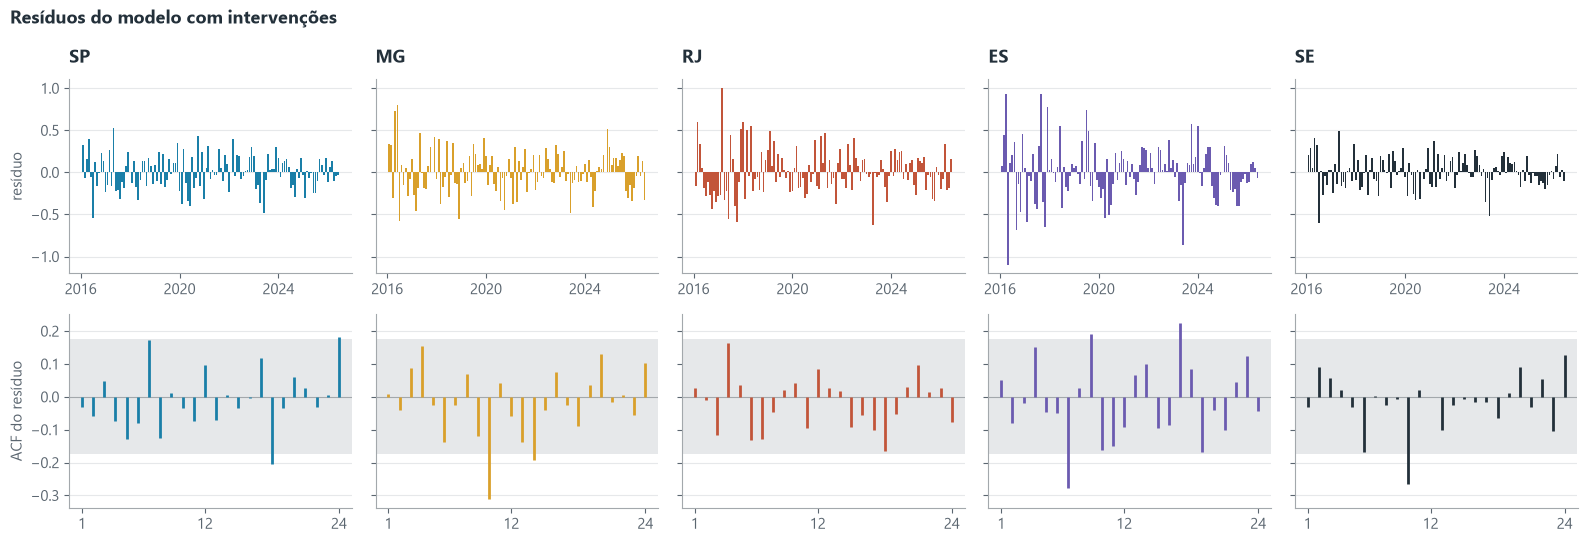

In [7]:
NL = 24
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), sharey="row")
for j, uf in enumerate(TODAS):
    e = residuos(modelo[uf])
    axes[0, j].bar(e.index, e, width=25, color=CORES[uf])
    axes[0, j].set_title(uf)
    axes[0, j].xaxis.set_major_locator(mdates.YearLocator(4))
    axes[0, j].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    banda = 1.96 / np.sqrt(len(e))
    axes[1, j].axhspan(-banda, banda, color=estilo.GRADE, lw=0)
    axes[1, j].axhline(0, color=estilo.NEUTRO, lw=0.8)
    axes[1, j].vlines(range(1, NL + 1), 0, acf(e, nlags=NL)[1:], color=CORES[uf], lw=2)
    axes[1, j].set_xticks([1, 12, 24])
axes[0, 0].set_ylabel("resíduo")
axes[1, 0].set_ylabel("ACF do resíduo")
fig.suptitle("Resíduos do modelo com intervenções", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "interv_residuos_uf.png")

**Leitura.**
- **SP, RJ e Sudeste passam:** Ljung-Box com p entre 0,16 e 0,45, e ACF dos resíduos dentro da banda.
- **MG tem θ₁ = −0,999, no limite de invertibilidade.** Um MA(1) com θ = −1 cancela a diferença: é o sinal clássico de sobrediferenciação. Com as quebras dentro do modelo, o log de MG se comporta como tendência determinística por partes mais ruído, e não como passeio aleatório. O Ljung-Box rejeita (p = 0,014), por causa de autocorrelação negativa perto do lag 10.
- **ES rejeita o Ljung-Box (p = 0,002).** Os maiores resíduos estão em 2016–2018, quando o estado conectava poucas usinas por mês e a série oscilava muito, e no fim da corrida em 2023.
- Os intervalos de MG e ES devem ser lidos com cautela. O Sudeste, que é a série usada nos cenários, tem resíduos bem comportados.

## 5. Efeito da lei

Duas perguntas:

1. **As três variáveis da lei, juntas, são diferentes de zero?** Teste de Wald conjunto.
2. **Quanto a lei mudou a potência adicionada por mês até jun/2026?** É a contribuição das variáveis da lei no último mês,
   $x_{\text{lei},T}'\beta_{\text{lei}}$, convertida em %.

O caminho "sem a lei" do gráfico é a série observada menos essa contribuição. Ele supõe que, sem a lei,
o ritmo de 2020–2021 teria continuado.

In [8]:
def efeito_lei(r, X, quando=None):
    g = X[LEI].iloc[-1] if quando is None else X[LEI].loc[quando]
    return g @ r.params[LEI], np.sqrt(g @ r.cov_params().loc[LEI, LEI] @ g)


tab_efeito = pd.DataFrame({
    uf: {"Wald p (lei = 0)": modelo[uf].wald_test(", ".join(f"{c} = 0" for c in LEI), scalar=True).pvalue,
         "efeito em jun/2026": fmt(*efeito_lei(modelo[uf], X), nivel)}
    for uf in TODAS}).T
tab_efeito

,Wald p (lei = 0),efeito em jun/2026
SP,0.907,-76% [-100; 1152]
MG,0.0,-45% [-77; 32]
RJ,0.579,-89% [-100; 198]
ES,0.773,-85% [-100; 3749]
SE,0.547,-69% [-97; 178]


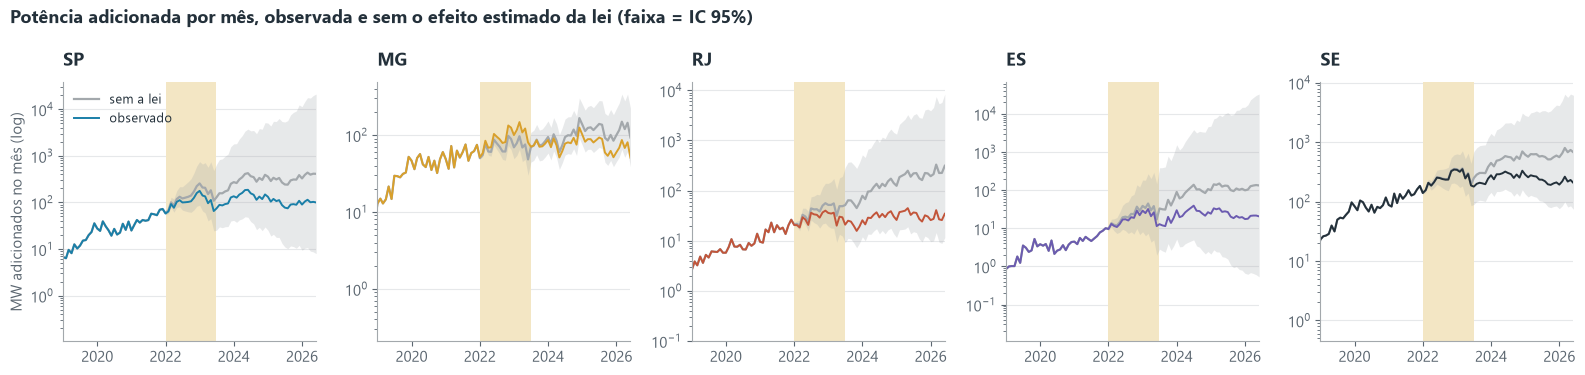

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, uf in zip(axes, TODAS):
    r = modelo[uf]
    contrib = X[LEI] @ r.params[LEI]
    se = np.sqrt(np.einsum("ij,jk,ik->i", X[LEI].to_numpy(), r.cov_params().loc[LEI, LEI].to_numpy(), X[LEI].to_numpy()))
    sem = y[uf] - contrib
    ax.axvspan(pd.Timestamp("2022-01"), pd.Timestamp("2023-06-30"), color=estilo.DESTAQUE, lw=0)
    ax.fill_between(idx, np.exp(sem - 1.96 * se), np.exp(sem + 1.96 * se), color=estilo.NEUTRO, alpha=0.25, lw=0)
    ax.plot(idx, np.exp(sem), color=estilo.NEUTRO, lw=1.6, label="sem a lei")
    ax.plot(idx, np.exp(y[uf]), color=CORES[uf], lw=1.4, label="observado")
    ax.set_yscale("log")
    ax.set_xlim(pd.Timestamp("2019-01"), idx[-1])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(uf)
axes[0].set_ylabel("MW adicionados no mês (log)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Potência adicionada por mês, observada e sem o efeito estimado da lei (faixa = IC 95%)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "interv_efeito_lei_uf.png")

**Leitura.**
- **A estimativa pontual é grande e tem o mesmo sinal em todas as UFs:** em jun/2026, a potência adicionada por mês fica de 45% (MG) a 89% (RJ) abaixo do caminho sem a lei. No Sudeste, 69% abaixo.
- **Com d = 1, só MG rejeita a hipótese de efeito nulo** (Wald p < 0,001). No Sudeste o intervalo vai de −97% a +178%.
- O gráfico mostra por que os intervalos abrem tanto. A faixa cinza cresce com o tempo, porque o caminho "sem a lei" é uma extrapolação da taxa de 2020–2021, e com d = 1 a incerteza dessa taxa se acumula a cada mês.
- **O caminho "sem a lei" supõe que o ritmo de 2020–2021 continuaria** (39% ao ano no Sudeste). Parte da desaceleração depois de 2023 pode vir de saturação do mercado ou de juros altos, que o modelo não separa da lei. Por isso a parte do efeito que vem da mudança de taxa é um teto. A parte mais atribuível à lei é a queda abrupta de nível no fim da corrida.

## 6. Robustez

**a) Fim da corrida em jan/2023**, a data do prazo de protocolo (e a quebra do Zivot-Andrews em SP), em vez de jun/2023.

**b) Tendência quebrada com erros estacionários (d = 0).** A fase 2 ficou com d = 1, mas avisou que quebras fazem os
testes enxergarem raiz unitária onde não há (Perron, 1989). Aqui as quebras estão no modelo, então vale testar
a alternativa: tendência linear por partes mais erros ARMA, com a ordem escolhida por AICc.
O AICc não compara modelos com d diferente, então a comparação é pelas estimativas e pelos resíduos.

In [10]:
NAO_CONVERGIU.clear()
X_jan = intervencoes("2023-01")
modelo_jan = {uf: ajustar(uf, X_jan, *ESCOLHA[uf]) for uf in TODAS}

ORDENS_D0 = [(1, 0, 0), (2, 0, 0), (1, 0, 1), (0, 0, 1), (0, 0, 2)]
modelo_d0 = {}
for uf in TODAS:
    fits = {o: ajustar(uf, X, o) for o in ORDENS_D0}
    modelo_d0[uf] = min(fits.values(), key=lambda r: r.aicc)
print("sem convergência:", NAO_CONVERGIU or "nenhum")

tab_rob = pd.DataFrame({
    uf: {"principal": fmt(*efeito_lei(modelo[uf], X), nivel),
         "fim em jan/2023": fmt(*efeito_lei(modelo_jan[uf], X_jan), nivel),
         "AICc jan/2023 − jun/2023": modelo_jan[uf].aicc - modelo[uf].aicc,
         "d = 0": fmt(*efeito_lei(modelo_d0[uf], X), nivel),
         "d = 0: ordem": str(modelo_d0[uf].model.order),
         "d = 0: Ljung-Box p (12)": acorr_ljungbox(modelo_d0[uf].resid, lags=[12],
                                                  model_df=n_arma(modelo_d0[uf]))["lb_pvalue"].iloc[0]}
    for uf in TODAS}).T
print("Efeito da lei em jun/2026 (% na potência adicionada por mês, IC 95%)")
tab_rob

C:\Users\gustavo.riedel\Documents\PUC\Mestrado\Séries_Temporais\Trabalho\código\IND2616-ProjetoMMGD\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\gustavo.riedel\Documents\PUC\Mestrado\Séries_Temporais\Trabalho\código\IND2616-ProjetoMMGD\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


sem convergência: ['MG (0, 0, 1)']
Efeito da lei em jun/2026 (% na potência adicionada por mês, IC 95%)


,principal,fim em jan/2023,AICc jan/2023 − jun/2023,d = 0,d = 0: ordem,d = 0: Ljung-Box p (12)
SP,-76% [-100; 1152],-75% [-100; 4518],-4.757,-88% [-98; -34],"(2, 0, 0)",0.248
MG,-45% [-77; 32],-41% [-74; 38],2.417,-45% [-75; 18],"(0, 0, 1)",0.048
RJ,-89% [-100; 198],-88% [-100; 205],-0.068,-92% [-99; -50],"(1, 0, 1)",0.238
ES,-85% [-100; 3749],-83% [-100; 5062],1.291,-76% [-98; 238],"(2, 0, 0)",0.0
SE,-69% [-97; 178],-66% [-95; 131],-4.429,-75% [-91; -31],"(2, 0, 0)",0.102


In [11]:
print("Queda de nível no fim da corrida (%, IC 95%)")
pd.DataFrame({
    uf: {"principal (jul/2023)": fmt(*combinacao(modelo[uf], {"nivel_fim": 1}), nivel),
         "fim em jan/2023 (fev/2023)": fmt(*combinacao(modelo_jan[uf], {"nivel_fim": 1}), nivel),
         "d = 0 (jul/2023)": fmt(*combinacao(modelo_d0[uf], {"nivel_fim": 1}), nivel)}
    for uf in TODAS}).T

Queda de nível no fim da corrida (%, IC 95%)


,principal (jul/2023),fim em jan/2023 (fev/2023),d = 0 (jul/2023)
SP,-2% [-47; 81],-20% [-98; 2993],-2% [-31; 39]
MG,-38% [-57; -9],-18% [-42; 15],-38% [-54; -16]
RJ,-30% [-77; 116],-22% [-55; 36],-24% [-62; 51]
ES,-41% [-81; 88],0% [-63; 168],-31% [-59; 16]
SE,-24% [-60; 45],-15% [-41; 21],-21% [-41; 5]


**Leitura.**
- **A estimativa pontual quase não muda** entre as três especificações: no Sudeste, −69% (principal), −66% (fim em jan/2023) e −75% (d = 0).
- **Fim da corrida:** o AICc prefere jan/2023 em SP (4,8 pontos) e no Sudeste (4,4). MG prefere jun/2023 (2,4), e RJ e ES ficam indiferentes. SP é o maior estado e domina o Sudeste, então a quebra de SP vem antes, no prazo de protocolo, como o Zivot-Andrews já indicava. Com o corte em jan/2023, a queda de nível de SP passa de −2% para −20%, com intervalo enorme.
- **Com d = 0, os intervalos fecham.** O efeito passa a ser significativo em SP (−88%), RJ (−92%) e no Sudeste (−75% [−91; −31]). A conclusão "a lei teve efeito" depende, portanto, de tratar a tendência como determinística por partes (d = 0) ou como estocástica (d = 1).
- O AICc não decide entre d = 0 e d = 1. A escolha fica para a fase 4, que compara os dois pela validação cruzada temporal. O θ ≈ −1 de MG é um argumento a favor de d = 0, pelo menos para MG.
- O único ajuste "sem convergência" é o MA(1) de MG com d = 0, que é o escolhido para MG. Ele dá a mesma queda de nível e a mesma mudança de taxa que a versão com d = 1 (−0,47 e −0,018 por mês), então o choque de MG não depende dele.

**c) Contrafactual.** Ajusta o modelo só até dez/2021, com a variável de 2020, e projeta jan/2022 a jun/2026 como se a
lei não existisse. Se a série observada sair do intervalo de previsão, há uma mudança que o regime de 2020–2021 não explica.

In [12]:
H = idx[idx > "2021-12"]
contraf = {}
for uf in TODAS:
    r = ajustar(uf, X[["taxa_2020"]], *ESCOLHA[uf], ate="2021-12")
    contraf[uf] = r.get_forecast(len(H), exog=X.loc[H, ["taxa_2020"]]).summary_frame(alpha=0.05)

tab_cf = pd.DataFrame({
    uf: {"observado / contrafactual em 2025–26": f"{100 * (np.exp((y[uf][H] - contraf[uf]['mean'])['2025':].mean()) - 1):.0f}%",
         "meses abaixo do IC 95% (de 54)": int((y[uf][H] < contraf[uf]["mean_ci_lower"]).sum()),
         "primeiro mês abaixo do IC": next((f"{m:%Y-%m}" for m in H if y[uf][m] < contraf[uf].loc[m, "mean_ci_lower"]), "—")}
    for uf in TODAS}).T
tab_cf

,observado / contrafactual em 2025–26,meses abaixo do IC 95% (de 54),primeiro mês abaixo do IC
SP,-73%,0,—
MG,-29%,6,2025-09
RJ,-84%,19,2023-10
ES,-78%,0,—
SE,-59%,13,2025-06


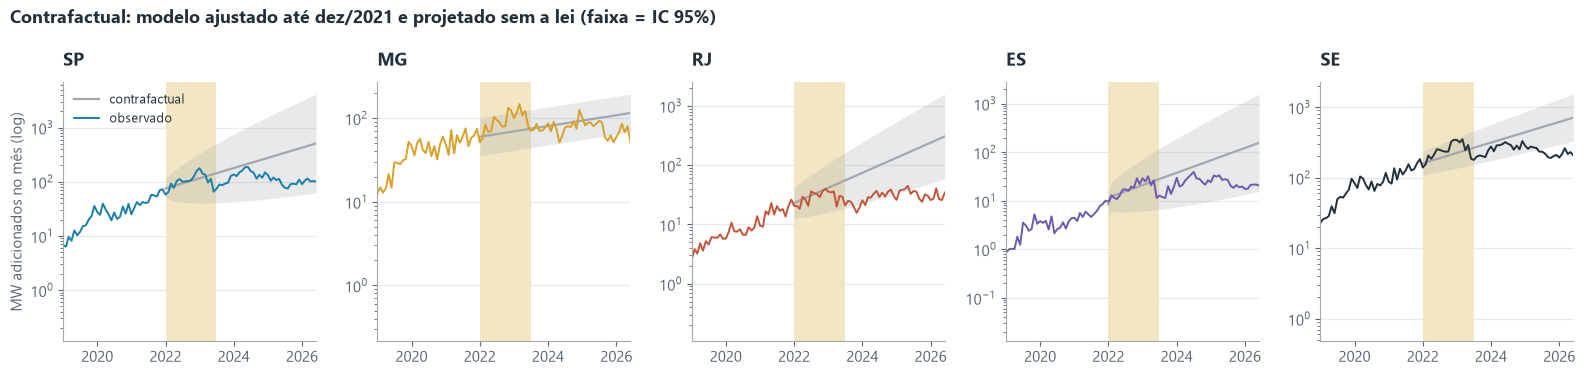

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, uf in zip(axes, TODAS):
    cf = contraf[uf]
    ax.axvspan(pd.Timestamp("2022-01"), pd.Timestamp("2023-06-30"), color=estilo.DESTAQUE, lw=0)
    ax.fill_between(H, np.exp(cf["mean_ci_lower"]), np.exp(cf["mean_ci_upper"]), color=estilo.NEUTRO, alpha=0.25, lw=0)
    ax.plot(H, np.exp(cf["mean"]), color=estilo.NEUTRO, lw=1.6, label="contrafactual")
    ax.plot(idx, np.exp(y[uf]), color=CORES[uf], lw=1.4, label="observado")
    ax.set_yscale("log")
    ax.set_xlim(pd.Timestamp("2019-01"), idx[-1])
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(uf)
axes[0].set_ylabel("MW adicionados no mês (log)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Contrafactual: modelo ajustado até dez/2021 e projetado sem a lei (faixa = IC 95%)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "interv_contrafactual_uf.png")

**Leitura.**
- **A corrida fica dentro do intervalo em todas as UFs.** O modelo de 2020–2021 já previa aquele nível de instalações, o que confirma que a corrida não acelerou o crescimento.
- **O afastamento aparece em 2025.** No Sudeste, o primeiro mês abaixo do intervalo de 95% é jun/2025. SP fica dentro do intervalo, que no ARIMA(1,1,0) é mais largo. Em MG é set/2025. RJ sai antes, em out/2023, logo depois do fim da corrida. ES nunca sai, porque o intervalo de ES é largo demais.
- Em 2025–2026, o observado fica em média 59% abaixo do contrafactual no Sudeste. O número é próximo do −69% do modelo com intervenções, por um caminho independente.
- O contrafactual tem a mesma limitação do modelo principal: supõe que o crescimento de 2020–2021 continuaria. A conclusão segura é que a queda observada em 2025–2026 é incompatível com aquele ritmo. Quanto dela é da lei e quanto é saturação, os dados não separam.

## 7. Choque para os cenários de 2029

A fase 5 aplica k × o choque do fim da corrida a partir de jan/2029, com k ∈ {0,5; 1; 2}. O choque tem duas partes:

- **queda de nível:** o coeficiente `nivel_fim`;
- **mudança de taxa contra o ritmo de 2020–21:** `taxa_corrida + taxa_fim`. O `taxa_fim` sozinho mede a mudança contra a taxa da
  corrida, que em MG foi inflada pela antecipação (65% ao ano contra 18% em 2020–21). Aplicado em 2029 sobre um regime sem corrida,
  ele contaria o fim da antecipação como se fosse efeito da regra nova. A soma mede quanto o crescimento depois de jul/2023 ficou
  abaixo do ritmo anterior à lei, que é o que uma regra nova poderia repetir.

O arquivo guarda as duas versões do modelo: **d = 0** (tendência quebrada), que a validação cruzada da fase 4 prefere à versão
com d = 1 em 4 das 5 séries, e **d = 1**, que a fase 5 usa como sensibilidade. Por UF e versão: ordem, coeficientes e covariância.

In [14]:
def choque_2029(r):
    """Queda de nível e mudança de taxa do fim da corrida, com a taxa medida contra o ritmo de 2020–21."""
    G = pd.DataFrame({"nivel": {"nivel_fim": 1.0}, "taxa": {"taxa_corrida": 1.0, "taxa_fim": 1.0}})
    G = G.reindex(r.params.index).fillna(0.0)
    return G.T @ r.params, G.T @ r.cov_params() @ G


linhas = []
for versao, modelos in [("d=0", modelo_d0), ("d=1", modelo)]:
    for uf in TODAS:
        b, V = choque_2029(modelos[uf])
        ordem = (modelos[uf].model.order, modelos[uf].model.seasonal_order)
        linhas.append({"d": versao, "uf": uf, "ordem": str(ordem), "b_nivel": b["nivel"], "b_taxa": b["taxa"],
                       "var_nivel": V.loc["nivel", "nivel"], "var_taxa": V.loc["taxa", "taxa"],
                       "cov_nivel_taxa": V.loc["nivel", "taxa"]})
choque = pd.DataFrame(linhas)
choque.to_csv(ROOT / "data" / "processed" / "fase3_choque_fim_corrida.csv", index=False)
choque.assign(ep_nivel=np.sqrt(choque.var_nivel), ep_taxa=np.sqrt(choque.var_taxa),
              fator_24_meses=np.exp(choque.b_nivel + 24 * choque.b_taxa))[
    ["d", "uf", "ordem", "b_nivel", "ep_nivel", "b_taxa", "ep_taxa", "fator_24_meses"]]

,d,uf,ordem,b_nivel,ep_nivel,b_taxa,ep_taxa,fator_24_meses
0,d=0,SP,"((2, 0, 0), (0, 0, 0, 0))",-0.023,0.181,-0.053,0.016,0.276
1,d=0,MG,"((0, 0, 1), (0, 0, 0, 0))",-0.474,0.156,-0.018,0.008,0.408
2,d=0,RJ,"((1, 0, 1), (0, 0, 0, 0))",-0.280,0.354,-0.047,0.019,0.244
3,d=0,ES,"((2, 0, 0), (0, 0, 0, 0))",-0.369,0.265,-0.041,0.024,0.257
4,d=0,SE,"((2, 0, 0), (0, 0, 0, 0))",-0.237,0.146,-0.035,0.010,0.337
5,d=1,SP,"((1, 1, 0), (0, 0, 0, 0))",-0.016,0.311,-0.025,0.044,0.543
6,d=1,MG,"((0, 1, 1), (0, 0, 0, 0))",-0.473,0.193,-0.018,0.010,0.408
7,d=1,RJ,"((0, 1, 1), (0, 0, 0, 0))",-0.351,0.571,-0.037,0.035,0.288
8,d=1,ES,"((0, 1, 2), (0, 0, 0, 0))",-0.523,0.589,-0.026,0.056,0.315
9,d=1,SE,"((0, 1, 1), (0, 0, 0, 0))",-0.270,0.328,-0.024,0.025,0.424


## Conclusões

1. **A desaceleração começou em 2020, antes da lei.** O crescimento do Sudeste caiu de ~200% para ~40% ao ano. É o resultado mais firme da fase e fica separado do efeito da lei.
2. **A corrida de 2022–2023 não acelerou o crescimento**, exceto em MG. Ela manteve o ritmo de 2020–2021 por mais um ano e meio.
3. **Depois da corrida, o crescimento para.** No Sudeste a taxa cai para ~4% ao ano. Em jun/2026, a potência adicionada por mês está ~70% abaixo do que o ritmo de 2020–2021 daria. O número se repete no contrafactual (−59%), com o fim da corrida em jan/2023 (−66%) e com d = 0 (−75%).
4. **A significância depende de d.** Com d = 1 (o modelo da fase 2), só MG tem efeito significativo. Com tendência quebrada e d = 0, SP, RJ e Sudeste também têm. A fase 4 escolhe entre os dois por validação cruzada temporal.
5. **O tamanho do efeito é um teto.** O "sem a lei" supõe que o ritmo de 2020–2021 continuaria. Saturação e juros também desaceleram a série e não são separáveis com estes dados. A parte mais atribuível à lei é a queda de nível no fim da corrida: −24% no Sudeste, mas com intervalo largo.
6. **Fim da corrida:** os dados preferem jan/2023 em SP e no Sudeste, e jun/2023 em MG. O modelo mantém jun/2023 porque a data vem do atraso entre o protocolo e a conexão, não do melhor ajuste (escolher a data pelo AICc seria circular, como no Bai-Perron), e o efeito total quase não muda (−69% contra −66% no Sudeste).

**Para os cenários de 2029 (fase 5):** o choque guardado é a queda de nível mais a mudança de taxa do fim da corrida, medida contra o ritmo de 2020–21 (`taxa_corrida + taxa_fim`), e não contra a taxa da corrida, que em MG foi inflada pela antecipação. A versão principal é a de d = 0; a de d = 1 fica como sensibilidade.

**Limitações:** séries curtas depois da corrida (36 meses); resíduos de MG e ES com autocorrelação; o cadastro da ANEEL só traz usinas ativas; e o modelo não tem variáveis econômicas (juros, preço do painel, tarifa).